# 모델 라우팅

**이 노트북에서 할 일**

1. 문의 글의 글자 수로 nano와 mini 가운데 보낼 모델을 고르는 함수를 만듭니다.
2. 기준 길이 30으로 문의 셋을 보내고, 기준 길이 하나만 0으로 바꿔 다시 보냅니다.
3. 두 실행의 답과, 모델마다 다른 요금표로 셈한 예상 비용을 견줍니다.

**준비물** — 이 노트북은 실제 모델에 요청을 여섯 번 보냅니다.
실행 1에서 세 번, 실행 2에서 세 번입니다.
모델별로는 `gpt-5.4-nano`에 두 번, `gpt-5.4-mini`에 네 번입니다.
프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
키가 없으면 키를 확인하는 셀에서 멈추고, 모델 요청은 나가지 않습니다.

요금표(2026-09-29 확인)로 어림한 비용은 여섯 번을 합쳐 0.001달러보다 적습니다.
청구 금액이 아니라, 교재를 만들 때 본 사용량으로 어림한 값입니다.
실행마다 답 글과 토큰 수가 달라질 수 있습니다.
교재를 만들 때 같은 요청 여섯을 노트북 밖에서 다섯 번 더 보내 보았고, 이를 흔들림 확인이라고 부릅니다.
걸린 시간은 재지 않았습니다.

실습 폴더의 도구 파일 `cost_tools.py`에서 함수 하나를 가져옵니다.
이 노트북은 파일을 쓰지 않습니다.

**기준 버전** — 첫 셀에서 패키지 셋을 설치합니다.
버전은 langchain 1.4.0, langchain-openai 1.6.0, python-dotenv 1.2.3입니다.
셋 모두 실습 폴더 잠금과 같은 버전입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2절의 모델 라우터를 보고 가설을 함께 세웁니다.
모델에 요청을 보내는 3·4절과 두 실행을 견주는 5절은 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch34-cost-rate-limits`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 초록 상자 문의 글 하나 글자 수 len에서 파란 상자 choose_model 글자 수와 기준 길이를 견줌으로 갑니다. 파란 상자에서 점선 둘이 갈라져, 기준 길이 이하이면 파란 상자 고른 이름 gpt-5.4-nano로, 기준 길이보다 길면 파란 상자 고른 이름 gpt-5.4-mini로 갑니다. 두 이름 상자는 send_inquiry로 보냄이라고 적힌 화살표로 보라 상자 gpt-5.4-nano와 보라 상자 gpt-5.4-mini에 각각 이어지고, 두 보라 상자에는 temperature=0 reasoning_effort none이 적혀 있는 그림](attachment:03-1-모델-라우터가-고르는-두-갈래.png)

위에서 아래로 읽습니다.
초록 상자는 셀에 적은 문의 글이고, 파란 상자는 우리가 정의한 함수와 그 함수가 고른 이름입니다.
점선 둘은 모델 라우터의 두 갈래입니다.
이름 상자에서 보라 상자로 가는 화살표가, 함수 send_inquiry가 요청을 보내는 자리입니다.
보라 상자는 이 절에서 실제로 부른 두 모델이고, 두 모델의 설정은 이름만 다릅니다.
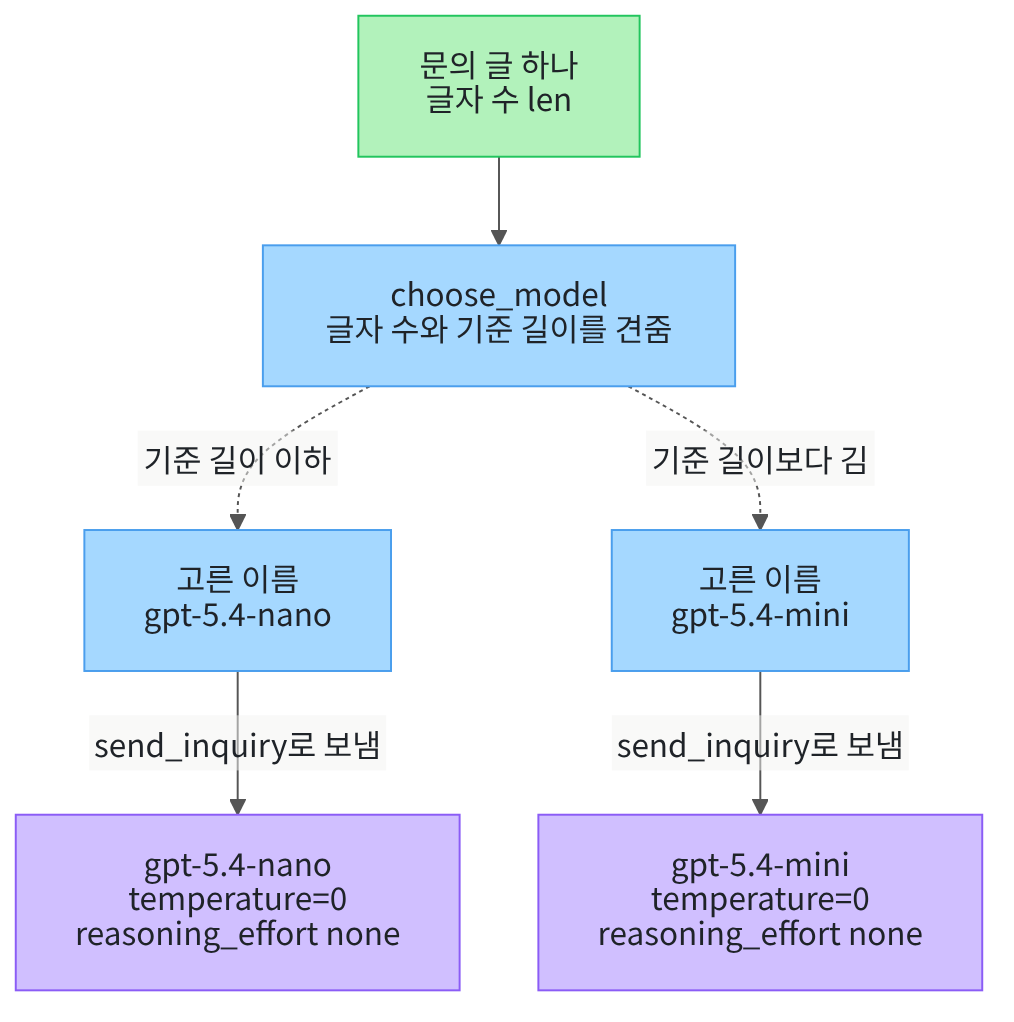

## 1. 준비

제목의 모델 라우팅은, 요청마다 어느 모델로 보낼지 코드가 고르는 일입니다.
이 절에서는 그 일을 하는 함수를 모델 라우터라고 부릅니다.
Ch 26 03절의 라우터는 요청을 분류해, 맞는 전문 에이전트에게 보내는 쪽이었습니다.
이 절의 모델 라우터는 같은 요청을 어느 모델로 보낼지만 고르고, 모델을 부르지 않습니다.

첫 셀은 패키지 셋을 설치하고 설치된 버전을 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-openai: 1.6.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.0`이 보입니다.
패키지 python-dotenv는 `.env` 파일에서 키를 읽을 때 씁니다.
세 패키지 모두 01절과 같은 버전입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
Ch 6 06절에서 배운 함수 `estimate_cost`는 도구 파일 `cost_tools.py`에서 가져옵니다.

In [2]:
# 모델 객체를 만들 함수와, 도구 파일의 함수를 가져옵니다
from langchain.chat_models import init_chat_model
# Ch 6 06절에서 배운 함수는 도구 파일에서 가져옵니다
from cost_tools import estimate_cost

print("가져온 이름:", "init_chat_model")
print("도구 파일에서 가져온 함수:", estimate_cost.__name__)

가져온 이름: init_chat_model
도구 파일에서 가져온 함수: estimate_cost


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost`가 보입니다.
01·02절처럼, 사용량과 요금표로 요청 한 번의 예상 비용을 셈하는 함수입니다.
이 절은 모델마다 요금표를 바꿔 가며 이 함수를 부릅니다.

앞에서 배운 함수는 `cost_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

다음 셀은 `.env` 파일에서 API 키를 읽고, 키가 있는지만 출력합니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄 `OPENAI_API_KEY 설정 여부: True`가 보입니다.
키 값은 출력하지 않고, 있는지만 봅니다.
키가 없으면 이 셀의 `assert`가 멈추고, 뒤 셀의 모델 요청도 나가지 않습니다.

다음 셀은 작은 모델 `gpt-5.4-nano`를 과정 표준 설정으로 준비합니다.
Ch 6 02절에서 모델 이름만 바꿔 불러 본 모델입니다.
객체를 만들 때는 모델 요청이 나가지 않습니다.

In [4]:
# 작은 모델 gpt-5.4-nano를 과정 표준 설정으로 준비합니다(요청은 나가지 않습니다)
nano_model = init_chat_model(
    "openai:gpt-5.4-nano",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", nano_model.model_name)
print("temperature:", nano_model.temperature)

모델 이름: gpt-5.4-nano
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-nano`, temperature `0.0`이 보입니다.
과정 표준 모델과 설정은 같고, 모델 이름만 다릅니다.
인자 `reasoning_effort="none"`은 모델이 답하기 전에 따로 생각하는 단계를 쓰지 않게 합니다.

다음 셀은 과정 표준 모델 `gpt-5.4-mini`를 같은 설정으로 준비합니다.
01절에서 쓴 모델입니다.

In [5]:
# 과정 표준 모델 gpt-5.4-mini를 같은 설정으로 준비합니다(요청은 나가지 않습니다)
mini_model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", mini_model.model_name)
print("temperature:", mini_model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-30에 이 두 모델로 실행한 결과입니다.
온도 값을 0으로 두어도 모델의 답이 매번 같다고 할 수는 없습니다.

두 모델 모두 생각하는 단계를 none으로 두었습니다.
공식 GPT-5.4 안내는 온도 칸을 none일 때만 받는다고 적습니다.
02절에서도 low와 온도 0을 함께 보낸 줄이 거절되었습니다.
그래서 이 절은 생각하는 단계를 그대로 두고, 모델 이름만 바꿔 고릅니다.

## 2. 문의 글과 모델 라우터

이 절도 01·02절처럼 책 가게의 문의를 배송, 환불, 결제 가운데 하나로 나눕니다.
짧고 흔한 문의는 싼 모델로도 답할 수 있을지 모릅니다.
그렇다고 모든 문의를 싼 모델로 보내면 답이 나빠질 수 있습니다.
그래서 문의마다 보낼 모델을 코드로 고르고, 답과 예상 비용을 함께 봅니다.

다음 셀은 문의 글 셋과, 문의마다 맞는 종류를 같은 차례로 적습니다.
문의마다 맞는 종류를 이 절에서는 정답 종류라고 부릅니다.
채점표 옆에 적어 둔 모범 답과 같습니다.
이 절 코드에서는 목록 `expected_types`의 세 값이 정답 종류입니다.

In [6]:
# 모델에 보낼 문의 글 셋과, 문의마다 맞는 종류(정답 종류)를 같은 차례로 적습니다
inquiries = [
    "주문한 책이 일주일째 오지 않습니다.",
    "받은 책이 찢어져 있어 돈을 되찾고 싶습니다.",
    "결제 창에서 카드 번호를 넣었는데 다음 단계로 넘어가지 않습니다.",
]
expected_types = ["배송", "환불", "결제"]
print("문의 글 수:", len(inquiries))
print("정답 종류:", expected_types)

문의 글 수: 3
정답 종류: ['배송', '환불', '결제']


**결과 읽기** — 출력 줄 `정답 종류: ['배송', '환불', '결제']`가 보입니다.
첫째와 둘째 문의는 01절 문의 글의 앞부분이고, 셋째는 02절 둘째 문의 글의 앞부분입니다.
답을 어떤 모양으로 쓸지 알려 주는 뒷부분은 조금 뒤에 따로 붙입니다.

다음 셀은 문의 글마다 글자 수를 셉니다.
모델 라우터는 이 글자 수를 보고 모델을 고릅니다.

In [7]:
# 문의 글마다 글자 수를 셉니다(모델 라우터가 기준 길이와 견줄 값입니다)
print("문의 | 글자 수")
for number in range(len(inquiries)):
    print(number + 1, "|", len(inquiries[number]))

문의 | 글자 수
1 | 20
2 | 25
3 | 36


**결과 읽기** — 라벨 줄 아래 세 줄이 문의마다 글자 수입니다.
차례대로 `1 | 20`, `2 | 25`, `3 | 36`입니다.
함수 `len`은 공백과 마침표까지 한 글자로 셉니다.

다음 셀은 문의 글 뒤에 붙일 답 형식 글을 정합니다.
답 형식 글은 답을 어떤 모양으로 쓸지 알려 주는 글입니다.
첫 문의로 요청 글 하나를 만들어, 모델에 실제로 갈 글을 봅니다.

In [8]:
# 문의 글 뒤에 붙일 답 형식 글을 정하고, 첫 문의로 요청 글 하나를 만들어 봅니다
answer_rule = "이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요."
first_request = inquiries[0] + " " + answer_rule
print("요청 글 1:", first_request)
print("요청 글 1의 글자 수:", len(first_request))

요청 글 1: 주문한 책이 일주일째 오지 않습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.
요청 글 1의 글자 수: 57


**결과 읽기** — 출력 줄 `요청 글 1의 글자 수: 57`이 보입니다.
문의 글 20글자, 공백 한 글자, 답 형식 글 36글자를 이었습니다.
이 요청 글은 01절 문의 글 1과 글자까지 같습니다.
둘째와 셋째 요청 글도 01절 문의 글 2, 02절 둘째 문의 글과 글자까지 같습니다.
한 낱말로 답하게 해서, 출력 토큰이 적게 나오게 했습니다.

다음 셀은 모델 라우터를 정의합니다.
모델 라우터는 요청마다 보낼 모델의 이름을 고르는 함수입니다.
복사할 장수가 적으면 작은 복사기로, 많으면 큰 복사기로 보내는 것과 같습니다.
이 절 코드에서는 함수 `choose_model`이 모델 라우터이고, 문의 글의 글자 수만 봅니다.

모델 라우터가 문의 글의 글자 수와 견주는 값을 이 절에서는 기준 길이라고 부릅니다.
Ch 13 03절과 Ch 18 02절에서 쓴 기준값의 하나입니다.
놀이기구 앞의 키 재는 막대처럼, 넘는지만 봅니다.
이 절 코드에서는 인자 `length_limit`가 기준 길이입니다.

In [9]:
# 문의 글의 글자 수를 기준 길이와 견주어, 보낼 모델의 이름을 고릅니다
def choose_model(inquiry, length_limit):
    # 이름을 먼저 nano로 두고, 기준 길이보다 긴 문의만 mini로 바꿉니다
    model_name = "gpt-5.4-nano"
    if len(inquiry) > length_limit:
        model_name = "gpt-5.4-mini"
    return model_name

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이름을 먼저 nano로 두고, 글자 수가 기준 길이보다 클 때만 mini로 바꿉니다.
그래서 글자 수가 기준 길이와 같으면 nano를 고릅니다.
함수는 모델 이름만 내놓고, 모델에 요청을 보내지 않습니다.
Ch 18 02절의 라우팅은 모델이 쓴 종류를 보고 갈래를 골랐지만, 이 함수는 모델을 부르기 전에 고릅니다.

다음 셀은 모델 라우터가 고른 이름으로 모델 객체를 찾을 수 있게, 이름과 객체를 딕셔너리에 담습니다.

In [10]:
# 모델 라우터가 고른 이름으로 모델 객체를 찾을 수 있게, 이름과 객체를 딕셔너리에 담습니다
models = {"gpt-5.4-nano": nano_model, "gpt-5.4-mini": mini_model}
print("고를 수 있는 모델:", list(models))

고를 수 있는 모델: ['gpt-5.4-nano', 'gpt-5.4-mini']


**결과 읽기** — 출력 줄 `고를 수 있는 모델: ['gpt-5.4-nano', 'gpt-5.4-mini']`가 보입니다.
함수 `list`에 딕셔너리를 넣으면 키만 모은 목록이 나옵니다.
키는 모델 라우터가 내놓는 이름과 같고, 값은 1절에서 만든 모델 객체입니다.

다음 셀은 두 모델의 요금표를 적습니다.
키 이름은 Ch 6 06절과 01절의 요금표와 같습니다.
모델 이름으로 요금표를 찾을 수 있게, 딕셔너리 하나에도 모읍니다.

In [11]:
# 두 모델의 공식 요금(100만 토큰당 달러)과 확인한 날짜를 적고, 모델 이름으로 찾게 모읍니다
pricing_date = "2026-09-29"
nano_prices = {"ordinary_input": 0.20, "cached_input": 0.02, "output": 1.25}
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
price_tables = {"gpt-5.4-nano": nano_prices, "gpt-5.4-mini": mini_prices}
print("요금 확인 날짜:", pricing_date)
print("nano 요금:", nano_prices)
print("mini 요금:", mini_prices)

요금 확인 날짜: 2026-09-29
nano 요금: {'ordinary_input': 0.2, 'cached_input': 0.02, 'output': 1.25}
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}


**결과 읽기** — 출력 줄 `nano 요금: {'ordinary_input': 0.2, 'cached_input': 0.02, 'output': 1.25}`가 보입니다.
단위는 100만 토큰당 달러이고, 세 값 모두 nano가 mini보다 작습니다.
입력은 0.20과 0.75달러, 출력은 1.25와 4.50달러입니다.
두 요금표 모두 Ch 6 06절의 요금표(2026-09-17)와 값이 같습니다.
요금은 바뀔 수 있어서 확인한 날짜를 함께 적습니다.

**가설** — 실행 1은 기준 길이를 30으로 둡니다.
그러면 20·25글자인 문의 둘은 nano로, 36글자인 문의는 mini로 갈 것입니다.
실행 2는 기준 길이 하나만 0으로 바꿔, 모든 문의를 mini로 보냅니다.
요금표의 세 값이 모두 nano가 작으므로, 실행 1의 예상 비용 합이 더 적을 것입니다.
세 문의는 짧고 뜻이 분명해서, 두 실행의 답은 같을 것이라고 예상합니다.

## 3. 실행 1 — 기준 길이 30

다음 셀은 기준 길이를 30으로 두고, 문의마다 모델 라우터가 고른 이름을 목록에 모읍니다.
문의마다 고른 모델 이름을 문의 차례대로 적은 목록을 이 절에서는 모델 배정이라고 부릅니다.
모임에서 사람마다 앉을 탁자를 적어 둔 자리표와 같습니다.
이 셀에서는 모델 요청이 나가지 않습니다.

In [12]:
# 실행 1: 기준 길이를 30으로 두고, 문의마다 모델 라우터가 고른 이름을 모읍니다(요청 없음)
length_limit = 30
run1_models = []
for inquiry in inquiries:
    run1_models.append(choose_model(inquiry, length_limit))
print("기준 길이:", length_limit)
print("모델 배정:", run1_models)
# 메서드 count는 목록에서 같은 값이 몇 번 나오는지 셉니다
print("nano로 보낼 요청 수:", run1_models.count("gpt-5.4-nano"))
print("mini로 보낼 요청 수:", run1_models.count("gpt-5.4-mini"))

기준 길이: 30
모델 배정: ['gpt-5.4-nano', 'gpt-5.4-nano', 'gpt-5.4-mini']
nano로 보낼 요청 수: 2
mini로 보낼 요청 수: 1


**결과 읽기** — 출력 줄 `모델 배정: ['gpt-5.4-nano', 'gpt-5.4-nano', 'gpt-5.4-mini']`이 보입니다.
가설대로 36글자인 셋째 문의만 기준 길이 30보다 길어 mini로 갑니다.
요청 수는 `nano로 보낼 요청 수: 2`, `mini로 보낼 요청 수: 1`입니다.
모델 배정은 글자 수와 기준 길이만으로 정해져, 실행할 때마다 같습니다.

다음 셀은 문의 하나를 고른 모델로 보내는 함수를 정의합니다.
딕셔너리 `models`에서 모델 객체를 찾고, 문의 글 뒤에 공백과 답 형식 글을 붙여 보냅니다.
Ch 6 01절처럼 글 하나를 메서드 `invoke`에 넣으면, 사용자 메시지 하나로 보냅니다.

In [13]:
# 고른 이름으로 모델 객체를 찾아, 문의 글 뒤에 답 형식 글을 붙여 보내고 응답을 내놓습니다
def send_inquiry(inquiry, model_name, models, answer_rule):
    chosen_model = models[model_name]
    request_text = inquiry + " " + answer_rule
    response = chosen_model.invoke(request_text)
    return response

**결과 읽기** — 정의 셀이라 출력이 없습니다.
모델 이름과 모델 객체 딕셔너리를 인자로 받으므로, 두 실행 모두 같은 함수로 보낼 수 있습니다.
함수는 받은 응답 객체를 그대로 내놓습니다.

다음 셀은 실행 1의 문의 셋을 모델 배정대로 하나씩 보냅니다.
응답마다 실제로 답한 모델의 이름을 `response_metadata`에서 꺼내, 고른 이름과 나란히 적습니다.
이 셀에서 모델 요청이 세 번 나갑니다.

In [14]:
# 실행 1: 문의 셋을 모델 배정대로 하나씩 보냅니다(모델 요청 3번)
print("문의 | 고른 모델 | 응답한 모델")
run1_responses = []
for number in range(len(inquiries)):
    response = send_inquiry(inquiries[number], run1_models[number], models, answer_rule)
    run1_responses.append(response)
    print(number + 1, "|", run1_models[number], "|", response.response_metadata["model_name"])

문의 | 고른 모델 | 응답한 모델


1 | gpt-5.4-nano | gpt-5.4-nano-2026-03-17


2 | gpt-5.4-nano | gpt-5.4-nano-2026-03-17


3 | gpt-5.4-mini | gpt-5.4-mini-2026-03-17


**결과 읽기** — 라벨 줄 아래 세 줄에서, 응답한 모델 이름이 고른 모델 이름으로 시작합니다.
첫 줄은 `1 | gpt-5.4-nano | gpt-5.4-nano-2026-03-17`입니다.
이름 끝의 날짜는 Ch 7 08절에서 본 날짜판입니다.
모델 라우터가 고른 모델로 요청이 실제로 갔다는 뜻입니다.
흔들림 확인 다섯 번에서도 모두 고른 모델이 답했습니다.

다음 셀은 응답 하나를 표 한 줄로 출력하는 함수를 정의합니다.
답, 정답 종류와 같은지, 입력·출력 토큰 수, 예상 비용을 차례로 적습니다.
예상 비용은 그 줄 모델의 요금표로 셈합니다.
요청 한 번의 값은 너무 작아서, Ch 6 06절처럼 같은 요청을 1,000번 보낼 때의 값으로 적습니다.

In [15]:
# 응답 하나의 답·정답 여부·토큰 수와, 같은 요청을 1,000번 보낼 때의 예상 비용을 한 줄로 출력하고 그 비용을 내놓습니다
def report_row(number, model_name, response, expected_type, price_tables):
    usage = response.usage_metadata
    prices = price_tables[model_name]
    cost = estimate_cost(usage, prices["ordinary_input"], prices["cached_input"], prices["output"])
    # 요청 한 번의 값은 너무 작아, Ch 6 06절처럼 같은 요청 1,000번의 값으로 적습니다
    request_count = 1000
    cost_1000 = cost * request_count
    print(number, "|", model_name, "|", response.text, "|", response.text == expected_type, "|", usage["input_tokens"], "|", usage["output_tokens"], "|", round(cost_1000, 6))
    return cost_1000

**결과 읽기** — 정의 셀이라 출력이 없습니다.
모델 이름으로 요금표를 찾으므로, nano가 답한 줄은 nano 요금표로 셈합니다.
답이 정답 종류와 같은지는 연산자 `==`로 글자까지 견줍니다.
모델이 답 끝에 마침표를 붙이면, 뜻은 같아도 같지 않다고 나옵니다.
함수는 1,000번 보낼 때의 예상 비용을 내놓아, 다음 셀에서 합을 셉니다.

다음 셀은 실행 1의 세 응답을 표로 출력하고, 1,000번 예상 비용의 합을 셉니다.

In [16]:
# 실행 1의 세 응답을 표로 출력하고, 1,000번 예상 비용의 합을 셉니다(요청 없음)
print("문의 | 모델 | 답 | 정답 종류와 같은가 | 입력 토큰 | 출력 토큰 | 1,000번 예상 비용(달러)")
run1_total = 0
for number in range(len(run1_responses)):
    cost_1000 = report_row(number + 1, run1_models[number], run1_responses[number], expected_types[number], price_tables)
    run1_total = run1_total + cost_1000
print("실행 1 합(달러):", round(run1_total, 6))

문의 | 모델 | 답 | 정답 종류와 같은가 | 입력 토큰 | 출력 토큰 | 1,000번 예상 비용(달러)
1 | gpt-5.4-nano | 배송 | True | 40 | 4 | 0.013
2 | gpt-5.4-nano | 환불 | True | 44 | 5 | 0.01505
3 | gpt-5.4-mini | 결제 | True | 44 | 5 | 0.0555
실행 1 합(달러): 0.08355


**결과 읽기** — 라벨 줄 아래 세 줄이 실행 1의 세 응답이고, 둘째 칸은 모델 배정 차례와 같습니다.
1,000번 예상 비용은 줄마다 그 줄 모델의 요금표로 셈했습니다.
넷째 칸은 답이 정답 종류와 글자까지 같은지입니다.
흔들림 확인 다섯 번에서는 세 문의 모두 정답 종류와 같은 답이 나왔습니다.

교재 출력에서는 답이 `배송`·`환불`·`결제`이고, 넷째 칸은 세 줄 모두 `True`였습니다.
입력 토큰 수는 `40`·`44`·`44`, 출력 토큰 수는 `4`·`5`·`5`였습니다.
1,000번 예상 비용은 `0.013`·`0.01505`·`0.0555`달러, 실행 1 합은 `0.08355`달러였습니다.
답과 토큰 수는 모델이 정하는 값이라 실행마다 달라질 수 있습니다.

## 4. 실행 2 — 기준 길이 0

실행 2는 값 하나만 바꿉니다.
바꾸는 값은 기준 길이이고, 30에서 0으로 내립니다.
문의 글·답 형식 글·모델 설정·요금표는 실행 1과 같습니다.

다음 셀은 기준 길이를 0으로 두고 모델 배정을 다시 만듭니다.
빈 글이 아닌 문의는 모두 0글자보다 길어서 mini로 갈 것입니다.
모든 요청을 과정 표준 모델 하나로 보내던 때와 같은 배정입니다.

In [17]:
# 실행 2: 기준 길이 하나만 0으로 바꾸고, 모델 배정을 다시 만듭니다(요청 없음)
length_limit = 0
run2_models = []
for inquiry in inquiries:
    run2_models.append(choose_model(inquiry, length_limit))
print("기준 길이:", length_limit)
print("모델 배정:", run2_models)
print("nano로 보낼 요청 수:", run2_models.count("gpt-5.4-nano"))
print("mini로 보낼 요청 수:", run2_models.count("gpt-5.4-mini"))

기준 길이: 0
모델 배정: ['gpt-5.4-mini', 'gpt-5.4-mini', 'gpt-5.4-mini']
nano로 보낼 요청 수: 0
mini로 보낼 요청 수: 3


**결과 읽기** — 출력 줄 `모델 배정: ['gpt-5.4-mini', 'gpt-5.4-mini', 'gpt-5.4-mini']`이 보입니다.
요청 수는 `nano로 보낼 요청 수: 0`, `mini로 보낼 요청 수: 3`입니다.
실행 1과 견주면 첫째와 둘째 문의만 nano에서 mini로 바뀌었습니다.
요청 수의 합은 두 실행 모두 셋입니다.

다음 셀은 실행 2의 문의 셋을 새 모델 배정대로 보냅니다.
실행 1과 같은 함수 `send_inquiry`를 씁니다.
이 셀에서 모델 요청이 세 번 나갑니다.

In [18]:
# 실행 2: 문의 셋을 새 모델 배정대로 하나씩 보냅니다(모델 요청 3번)
print("문의 | 고른 모델 | 응답한 모델")
run2_responses = []
for number in range(len(inquiries)):
    response = send_inquiry(inquiries[number], run2_models[number], models, answer_rule)
    run2_responses.append(response)
    print(number + 1, "|", run2_models[number], "|", response.response_metadata["model_name"])

문의 | 고른 모델 | 응답한 모델


1 | gpt-5.4-mini | gpt-5.4-mini-2026-03-17


2 | gpt-5.4-mini | gpt-5.4-mini-2026-03-17


3 | gpt-5.4-mini | gpt-5.4-mini-2026-03-17


**결과 읽기** — 라벨 줄 아래 세 줄 모두 고른 모델이 `gpt-5.4-mini`입니다.
응답한 모델도 세 줄 모두 `gpt-5.4-mini-2026-03-17`입니다.
첫째와 둘째 문의는 실행 1에서 nano가 답했던 문의입니다.
흔들림 확인 다섯 번에서도 모두 고른 모델이 답했습니다.

다음 셀은 실행 2의 세 응답을 실행 1과 같은 모양의 표로 출력합니다.

In [19]:
# 실행 2의 세 응답을 실행 1과 같은 모양의 표로 출력하고, 합을 셉니다(요청 없음)
print("문의 | 모델 | 답 | 정답 종류와 같은가 | 입력 토큰 | 출력 토큰 | 1,000번 예상 비용(달러)")
run2_total = 0
for number in range(len(run2_responses)):
    cost_1000 = report_row(number + 1, run2_models[number], run2_responses[number], expected_types[number], price_tables)
    run2_total = run2_total + cost_1000
print("실행 2 합(달러):", round(run2_total, 6))

문의 | 모델 | 답 | 정답 종류와 같은가 | 입력 토큰 | 출력 토큰 | 1,000번 예상 비용(달러)
1 | gpt-5.4-mini | 배송 | True | 40 | 4 | 0.048
2 | gpt-5.4-mini | 환불 | True | 44 | 5 | 0.0555
3 | gpt-5.4-mini | 결제 | True | 44 | 5 | 0.0555
실행 2 합(달러): 0.159


**결과 읽기** — 라벨 줄 아래 세 줄 모두 mini 요금표로 셈했습니다.
셋째 문의는 두 실행 모두 mini로 보냈으므로, 실행 1의 셋째 줄과 같은 요금표를 썼습니다.
흔들림 확인 다섯 번에서는 세 문의 모두 정답 종류와 같은 답이 나왔습니다.

교재 출력에서는 답이 `배송`·`환불`·`결제`이고, 넷째 칸은 세 줄 모두 `True`였습니다.
1,000번 예상 비용은 `0.048`·`0.0555`·`0.0555`달러, 실행 2 합은 `0.159`달러였습니다.
첫째 문의의 비용은 실행 1의 `0.013`달러에서 `0.048`달러로 커졌습니다.
토큰 수가 같아도, 요금표가 mini로 바뀌었기 때문입니다.

## 5. 두 실행 견주기

다음 셀은 문의마다 두 실행의 모델 배정과 답을 나란히 봅니다.
연산자 `!=`는 두 값이 다르면 True를 냅니다.

In [20]:
# 문의마다 두 실행의 모델 배정과 답을 나란히 봅니다(요청 없음)
print("문의 | 실행 1 모델 | 실행 2 모델 | 모델이 바뀌었는가 | 두 답이 같은가")
for number in range(len(inquiries)):
    # 연산자 !=는 두 값이 다르면 True를 냅니다
    changed = run1_models[number] != run2_models[number]
    same_answer = run1_responses[number].text == run2_responses[number].text
    print(number + 1, "|", run1_models[number], "|", run2_models[number], "|", changed, "|", same_answer)

문의 | 실행 1 모델 | 실행 2 모델 | 모델이 바뀌었는가 | 두 답이 같은가
1 | gpt-5.4-nano | gpt-5.4-mini | True | True
2 | gpt-5.4-nano | gpt-5.4-mini | True | True
3 | gpt-5.4-mini | gpt-5.4-mini | False | True


**결과 읽기** — 라벨 줄 아래 넷째 칸은 차례대로 `True`, `True`, `False`입니다.
기준 길이 하나만 바꾸자 첫째와 둘째 문의의 모델이 바뀌었습니다.
셋째 문의는 두 실행 모두 mini였습니다.
모델 배정은 코드가 정하므로 실행할 때마다 같습니다.

다섯째 칸은 두 실행의 답 글이 같은지이고, 교재 출력에서는 세 줄 모두 `True`였습니다.
흔들림 확인 다섯 번에서도 모두 같았습니다.
그래도 답 글은 모델이 쓰는 값이라, 실행마다 달라질 수 있습니다.

다음 셀은 같은 문의를 보낸 두 요청의 입력 토큰 수를 견줍니다.
첫째와 둘째 문의는 nano와 mini에 한 번씩, 셋째 문의는 mini에 두 번 보냈습니다.

In [21]:
# 같은 문의를 보낸 두 요청의 입력 토큰 수를 견줍니다(요청 없음)
print("문의 | 실행 1 입력 토큰 | 실행 2 입력 토큰 | 같은가")
for number in range(len(inquiries)):
    first_input = run1_responses[number].usage_metadata["input_tokens"]
    second_input = run2_responses[number].usage_metadata["input_tokens"]
    print(number + 1, "|", first_input, "|", second_input, "|", first_input == second_input)

문의 | 실행 1 입력 토큰 | 실행 2 입력 토큰 | 같은가
1 | 40 | 40 | True
2 | 44 | 44 | True
3 | 44 | 44 | True


**결과 읽기** — 라벨 줄 아래 세 줄의 마지막 칸이 두 요청의 입력 토큰 수가 같은지입니다.
흔들림 확인 다섯 번에서는 세 문의 모두 같았습니다.

교재 출력에서는 세 줄 모두 `True`였고, 입력 토큰 수는 문의마다 `40`·`44`·`44`였습니다.
이번 실행에서는 같은 글을 보내면 두 모델의 입력 토큰 수가 같았습니다.
그래서 두 실행의 예상 비용 차이는 토큰 수가 아니라 요금표에서 왔습니다.

다음 셀은 두 실행의 1,000번 예상 비용 합을 견줍니다.

In [22]:
# 두 실행의 1,000번 예상 비용 합을 견줍니다(요청 없음)
print("실행 1 합(달러):", round(run1_total, 6))
print("실행 2 합(달러):", round(run2_total, 6))
print("실행 1의 합이 더 적은가:", run1_total < run2_total)

실행 1 합(달러): 0.08355
실행 2 합(달러): 0.159
실행 1의 합이 더 적은가: True


**결과 읽기** — 마지막 줄은 실행 1의 합이 실행 2보다 적은지입니다.
흔들림 확인 다섯 번에서는 모두 실행 1의 합이 더 적었습니다.

교재 출력에서는 `실행 1의 합이 더 적은가: True`였고, 합은 `0.08355`와 `0.159`달러였습니다.
합의 값은 토큰 수에 따라 달라지므로, 결론에는 참·거짓만 씁니다.

다음 셀은 실행 1 첫 응답의 사용량 하나를, 두 모델의 요금표로 각각 셈합니다.
사용량은 같고 요금표만 다른 셈입니다.

In [23]:
# 실행 1 첫 응답의 사용량 하나를 두 요금표로 각각 셈해, 1,000번 예상 비용을 견줍니다(요청 없음)
same_usage = run1_responses[0].usage_metadata
nano_cost = estimate_cost(same_usage, nano_prices["ordinary_input"], nano_prices["cached_input"], nano_prices["output"])
mini_cost = estimate_cost(same_usage, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"])
request_count = 1000
print("nano 요금표로 센 값(달러):", round(nano_cost * request_count, 6))
print("mini 요금표로 센 값(달러):", round(mini_cost * request_count, 6))
print("nano 요금표로 센 값이 더 적은가:", nano_cost < mini_cost)

nano 요금표로 센 값(달러): 0.013
mini 요금표로 센 값(달러): 0.048
nano 요금표로 센 값이 더 적은가: True


**결과 읽기** — 마지막 줄 `nano 요금표로 센 값이 더 적은가: True`가 보입니다.
요금표의 세 값이 모두 nano가 작으므로, 사용량이 같으면 nano 쪽이 늘 적습니다.
이 참·거짓은 토큰 수가 0보다 크기만 하면 요금표가 정합니다.

교재 출력에서는 nano `0.013`달러, mini `0.048`달러였습니다.
입력 토큰이 많은 요청일수록 두 값의 차이가 커집니다.

**결론** — 바꾼 값은 모델 라우터의 기준 길이 하나였습니다.
기준 길이 30에서는 nano 둘·mini 하나로, 0에서는 mini 셋으로 문의가 갔습니다.
요청 수의 합은 두 실행 모두 셋이고, 같은 사용량이면 nano 요금표로 센 값이 늘 적습니다.
흔들림 확인 다섯 번과 새 커널 두 번에서 모두, 여섯 답이 정답 종류와 같았고 실행 1의 합이 더 적었습니다.
다만 문의 셋은 작은 표본이라, 다른 문의에서도 nano의 답이 맞는다고 할 수는 없습니다.

## 정리

1. 모델 라우터는 문의 글의 글자 수를 기준 길이와 견주어 모델 이름만 고르고, 요청은 따로 보냅니다.
2. 기준 길이 하나를 바꾸면 모델 배정과 모델별 요청 수가 바뀌고, 예상 비용은 모델마다 다른 요금표로 셉니다.
3. 싼 모델로 보낸 문의의 답이 정답 종류와 같은지 함께 확인해야, 줄인 비용에 뜻이 있습니다.

04절에서는 요청 제한(429)을 받았을 때 다시 보내는 횟수와 한꺼번에 보내는 수를 다룹니다.